<a href="https://colab.research.google.com/github/hkaido0718/SupportRestriction/blob/atsuki-update_functions_documents/MediationModel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# The `MediationModel` class: a mediator vector with no direct treatment effect
Let $Y$ denote an outcome and $D$ an assigned treatment, each with a finite support, and let $M=(M_1,\dots,M_J)$ be a vector of mediators whose support is the Cartesian product of finite coordinate supports. Let $M(d)$ and $Y(m,d)$ denote the potential mediators and the potential outcomes, with observed responses $M=M(D)$ and $Y=Y(M(D),D)$, where the full vector $\big((M(d))_d,(Y(m,d))_{m,d}\big)$ is independent of $D$.

The `MediationModel` class in `mediation_model.py` imposes, for a nonempty set $S$ of selected mediator coordinates (`active_mediators`, default `"all"`),

\begin{align}
Y(m,d)=g(m_S)\qquad\text{for every mediator vector } m \text{ and treatment value } d,
\end{align}

where $m_S$ collects the selected coordinates of $m$ and $g$ is unrestricted. The outcome responds to the selected mediator coordinates only, so there is no direct effect of $D$ on $Y$. Selecting a proper subset of the coordinates additionally excludes the remaining coordinates from the outcome response; it does not restrict how any mediator, selected or not, responds to $D$, and no monotonicity is imposed.

Each model is represented by a graph $G$ whose nodes are the observable events $(y,m,d)$, with $m$ a tuple. `build_graph()` joins two nodes with different treatment values exactly when the pair is not rejected by the mediation rule: equal selected profiles $m_S=m'_S$ with different outcomes $y\neq y'$ are incompatible, because both events would fix $g(m_S)$, and every other cross-treatment pair is compatible (Method 1 of Kaido and Ponomarev, 2025). Nodes with the same treatment value are never joined. The class only builds the graph; `GraphAnalyzer` from `graph_analysis_utils.py` is imported separately to plot it, list the maximal independent sets (MISs) and check regularity.

In [1]:
# Inside a local checkout, the modules are importable from the working directory.
# Anywhere else (for example Google Colab), fetch the repository, check out the
# branch or commit under review, and add it to the path.
import os
import sys

REPO_URL = "https://github.com/hkaido0718/SupportRestriction.git"
REPO_REF = "atsuki-update_functions_documents"  # branch, tag or commit to load; use "main" once merged

if not os.path.isfile("mediation_model.py"):
    if not os.path.isdir("SupportRestriction"):
        !git clone --quiet {REPO_URL}
    !git -C SupportRestriction checkout --quiet {REPO_REF}
    sys.path.insert(0, os.path.abspath("SupportRestriction"))

In [2]:
# Confirm which checkout the modules are imported from.
import subprocess

import mediation_model
import graph_analysis_utils

for module in (mediation_model, graph_analysis_utils):
    print(f"{module.__name__:22s} imported from {os.path.relpath(module.__file__)}")

repo_dir = os.path.dirname(os.path.abspath(mediation_model.__file__))

def git(*args):
    result = subprocess.run(["git", "-C", repo_dir, *args], capture_output=True, text=True)
    return result.stdout.strip() or "?"

print(f"checkout: {git('rev-parse', '--abbrev-ref', 'HEAD')} at commit {git('rev-parse', '--short', 'HEAD')}")

mediation_model        imported from mediation_model.py
graph_analysis_utils   imported from graph_analysis_utils.py
checkout: atsuki-update_functions_documents at commit f7e3c4d


## 1. Binary outcome, one binary mediator, binary treatment
With $Y,M_1,D\in\{0,1\}$ there are 8 nodes in two treatment groups, hence $4\times 4=16$ cross-group pairs. The mediation rule removes the four pairs with equal mediator value and unequal outcome, $(y,m,0)$ with $(1-y,m,1)$, so the graph has 12 edges. `repr(model)` shows the configuration, with `"all"` resolved to the coordinate indices, and `summary()` spells out the assumptions.

In [3]:
from itertools import combinations

from mediation_model import MediationModel
from graph_analysis_utils import GraphAnalyzer

model_1 = MediationModel(y_support=(0, 1), m_supports=((0, 1),), d_support=(0, 1))
graph_1 = model_1.build_graph()
print(f"nodes = {graph_1.number_of_nodes()}, edges = {graph_1.number_of_edges()}")
print(repr(model_1))
print()
print(model_1.summary())

nodes = 8, edges = 12
MediationModel(y_support=(0, 1), m_supports=((0, 1),), d_support=(0, 1), active_mediators=(0,))

MediationModel: discrete mediation model with a mediator vector (Kaido and Ponomarev, 2025)
  Outcome support Y:    (0, 1)
  Treatment support D:  (0, 1)
  Mediator coordinates: 1, M = (M1,)
    M1: (0, 1)
  Mediator support M:   Cartesian product, 2 vectors
  Selected mediators:   (0,) -> M1
  Nodes (y, m, d):      8
  Potential responses: M(d) and Y(m, d); observed M = M(D), Y = Y(M(D), D).
  Assumptions:
    - Mediation: imposed (always). Y(m, d) = g(m): the outcome responds to
      the whole mediator vector, so there is no direct effect of D on Y.
    - Every mediator coordinate is selected; none is excluded from the
      outcome response.
    - No monotonicity is imposed; the potential mediators M(d) are
      unrestricted.
  Maintained (not a pairwise rule): the full potential-response vector
    ((M(d))_d, (Y(m, d))_{m, d}) is independent of D.
  Graph: build_

### Plot

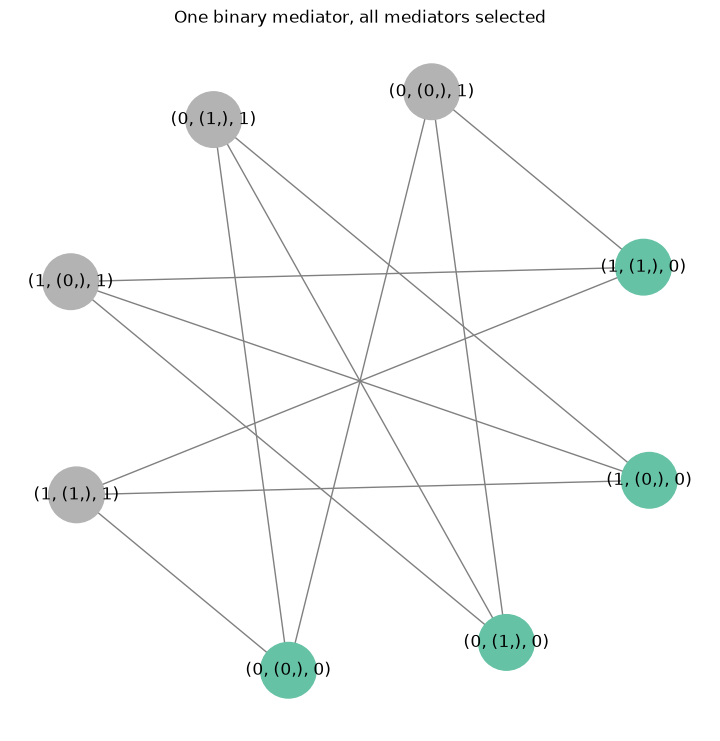

In [4]:
analyzer_1 = GraphAnalyzer(graph_1, group_fn=model_1.group_fn)
analyzer_1.plot_grouped_on_circle(title="One binary mediator, all mediators selected", node_size=1600, figsize=(7, 7))

### Maximal independent sets and the testable implications
Each maximal independent set that spans both treatment groups gives an inequality: the conditional probabilities of its events, one treatment group at a time, sum to at most one. The model's `format_inequalities` writes each set as that inequality: `MediationModel` knows which outcome, mediator vector and treatment value every node carries, so no notebook helper is needed. When the set contains every value of the unselected mediator coordinates for a given outcome and selected profile, the events are merged into a probability that mentions the selected coordinates only, and when every outcome of a profile is present they merge further into $P(M_S=s\mid D=d)$.

In [5]:
mis_list_1 = analyzer_1.find_mis_excluding_single_group()
print(f"MISs spanning both treatment groups: {len(mis_list_1)}")
for inequality in model_1.format_inequalities(mis_list_1):
    print("  ", inequality)


MISs spanning both treatment groups: 4
   P(Y=1, M1=1 | D=0) + P(Y=0, M1=1 | D=1) <= 1
   P(Y=0, M1=1 | D=0) + P(Y=1, M1=1 | D=1) <= 1
   P(Y=1, M1=0 | D=0) + P(Y=0, M1=0 | D=1) <= 1
   P(Y=0, M1=0 | D=0) + P(Y=1, M1=0 | D=1) <= 1


The four inequalities are, for each mediator value $m$ and each outcome $y$,

\begin{align}
P(Y=y,M_1=m\mid D=0)+P(Y=1-y,M_1=m\mid D=1)\leqslant 1 .
\end{align}

They are Pearl's instrumental inequalities with the mediator in the role of the treatment and the treatment in the role of the instrument: full mediation, $Y(m,d)=g(m)$, is the exclusion restriction of the IV model with $(M,D)$ in place of $(D,Z)$, and the graph is the one `IVModel` builds under exclusion alone after relabelling $(y,(m,),d)$ as $(y,m,d)$. The tests check this equality.

### Regularity
Condition 2 of the paper (every maximal clique is a support point) holds for this class by the completion argument in the module docstring, not by a numerical check: `enumerate_cliques_and_check` below re-applies the pairwise rule inside every maximal clique, which a graph built by Method 1 passes automatically, and is reported for comparability with the other notebooks. The substantive numerical check is perfectness: with two treatment values the graph is bipartite, hence perfect, so the four inequalities are sharp.

In [6]:
rows = analyzer_1.enumerate_cliques_and_check(model_1.violate_pairwise_fn)
print(f"perfect = {analyzer_1.is_perfect()}, maximal cliques = {len(rows)}, "
      f"every maximal clique passes the pairwise rule = {all(r['satisfies_condition'] for r in rows)}")

perfect = True, maximal cliques = 12, every maximal clique passes the pairwise rule = True


## 2. Two binary mediators: all mediators selected versus $M_1$ only
With $M\in\{0,1\}^2$ there are 16 nodes and $8\times 8=64$ cross-group pairs. With both mediators selected, the rule removes the eight pairs with equal mediator vector and unequal outcome, leaving 56 edges. With `active_mediators=(0,)` only $M_1$ enters the outcome response, so equal $M_1$ with unequal outcome is incompatible whatever $M_2$ does: $2\times 2^2\times 2=16$ pairs are removed and 48 edges remain. The second graph is a subgraph of the first, because excluding a mediator from the outcome response is a stronger restriction. `summary()` names the unselected coordinate.

In [7]:
two = dict(y_support=(0, 1), m_supports=((0, 1), (0, 1)), d_support=(0, 1))
models_2 = {
    "All mediators selected": MediationModel(**two, active_mediators="all"),
    "M1 only": MediationModel(**two, active_mediators=(0,)),
}
graphs_2 = {name: model.build_graph() for name, model in models_2.items()}

for name, G in graphs_2.items():
    print(f"{name:24s} {models_2[name].active_mediators!s:7s} nodes = {G.number_of_nodes()}, edges = {G.number_of_edges()}")
print()
print(models_2["M1 only"].summary())

All mediators selected   (0, 1)  nodes = 16, edges = 56
M1 only                  (0,)    nodes = 16, edges = 48

MediationModel: discrete mediation model with a mediator vector (Kaido and Ponomarev, 2025)
  Outcome support Y:    (0, 1)
  Treatment support D:  (0, 1)
  Mediator coordinates: 2, M = (M1, M2)
    M1: (0, 1)
    M2: (0, 1)
  Mediator support M:   Cartesian product, 4 vectors
  Selected mediators:   (0,) -> M1
  Nodes (y, m, d):      16
  Potential responses: M(d) and Y(m, d); observed M = M(D), Y = Y(M(D), D).
  Assumptions:
    - Mediation: imposed (always). Y(m, d) = g(m_S) with S = (M1,): the outcome
      responds to the selected mediator coordinates only, so there is no
      direct effect of D on Y.
    - Unselected coordinates (M2) do not enter the outcome response;
      they may still respond to D.
    - No monotonicity is imposed; the potential mediators M(d) are
      unrestricted.
  Maintained (not a pairwise rule): the full potential-response vector
    ((M(d))

### Selected pairs
The pairs below are the ones listed in the specification. The first fixes $g(0,0)$ to two different values and is incompatible under either selection. The second differs in $M_2$ only: compatible when both mediators are selected, incompatible when $M_1$ alone determines the outcome. The third differs in $M_1$ and the fourth has equal outcomes, so both are compatible under either selection. Each pair is checked in both argument orders.

In [8]:
pairs = [
    ((0, (0, 0), 0), (1, (0, 0), 1), "equal mediators, outcomes differ"),
    ((0, (0, 0), 0), (1, (0, 1), 1), "only M2 differs, outcomes differ"),
    ((0, (0, 0), 0), (1, (1, 0), 1), "M1 differs, outcomes differ"),
    ((0, (0, 0), 0), (0, (0, 1), 1), "only M2 differs, equal outcomes"),
]
print(f"{'pair':44s} {'all selected':14s} {'M1 only':14s} reason")
for u, v, reason in pairs:
    cells = []
    for name, model in models_2.items():
        G = graphs_2[name]
        both_orders = G.has_edge(u, v) and G.has_edge(v, u)
        assert model.violates_mediation(u, v) is model.violates_mediation(v, u) is (not both_orders)
        cells.append("edge" if both_orders else "no edge")
    print(f"{str(u) + ' ' + str(v):44s} {cells[0]:14s} {cells[1]:14s} {reason}")

pair                                         all selected   M1 only        reason
(0, (0, 0), 0) (1, (0, 0), 1)                no edge        no edge        equal mediators, outcomes differ
(0, (0, 0), 0) (1, (0, 1), 1)                edge           no edge        only M2 differs, outcomes differ
(0, (0, 0), 0) (1, (1, 0), 1)                edge           edge           M1 differs, outcomes differ
(0, (0, 0), 0) (0, (0, 1), 1)                edge           edge           only M2 differs, equal outcomes


### Plots

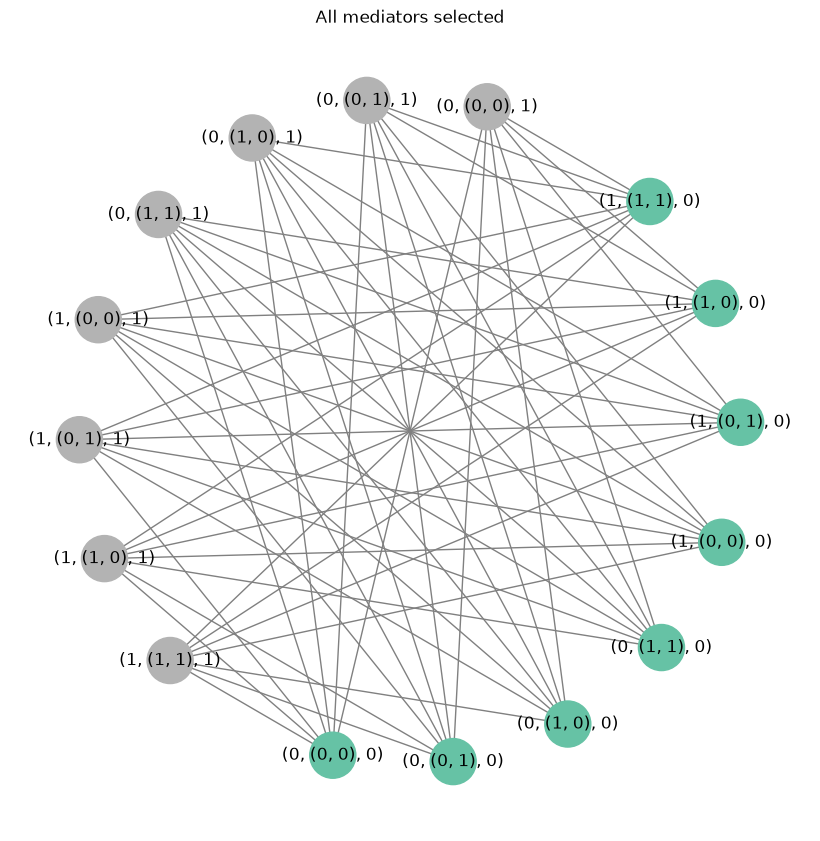

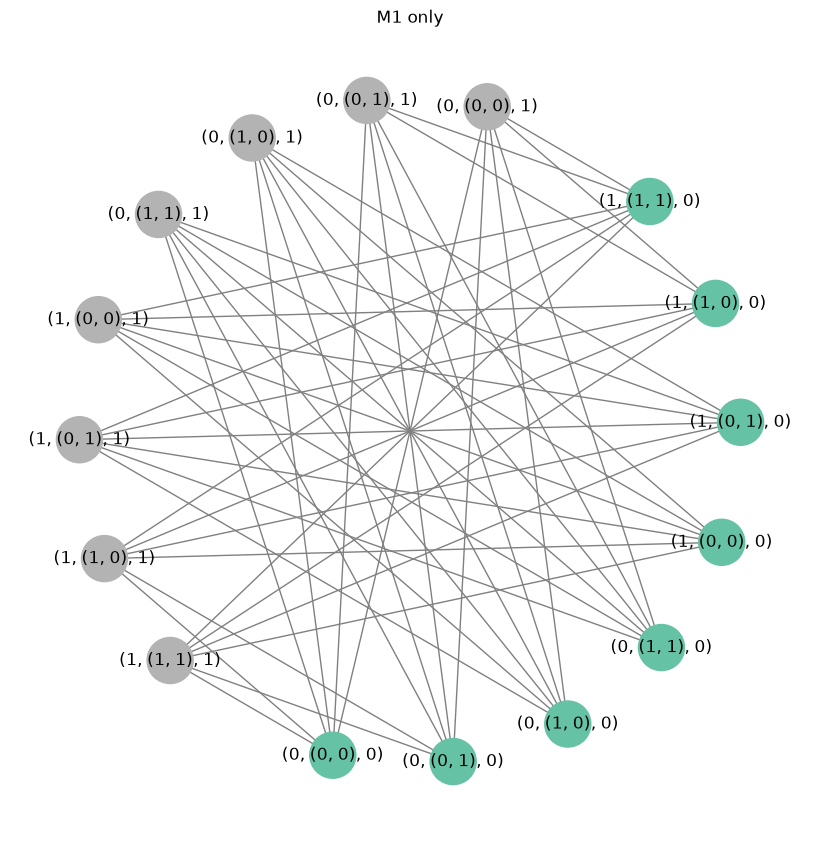

In [9]:
for name, G in graphs_2.items():
    analyzer = GraphAnalyzer(G, group_fn=models_2[name].group_fn)
    analyzer.plot_grouped_on_circle(title=name, node_size=1100, figsize=(8, 8))

### Maximal independent sets and the testable implications
With both mediators selected there are eight MISs, one per mediator vector $m$ and outcome $y$:

\begin{align}
P(Y=y,M=m\mid D=0)+P(Y=1-y,M=m\mid D=1)\leqslant 1 .
\end{align}

With $M_1$ alone selected, each MIS contains both values of $M_2$, so the events merge and there are four inequalities,

\begin{align}
P(Y=y,M_1=m_1\mid D=0)+P(Y=1-y,M_1=m_1\mid D=1)\leqslant 1 ,
\end{align}

the inequalities of Section 1 with $M_2$ marginalized out. Each of them implies two of the eight inequalities above, since its left-hand side is the sum of theirs: excluding $M_2$ from the outcome response strengthens the testable implications.

In [10]:
for name, G in graphs_2.items():
    analyzer = GraphAnalyzer(G, group_fn=models_2[name].group_fn)
    mis_list = analyzer.find_mis_excluding_single_group()
    print(f"=== {name}: {len(mis_list)} MISs spanning both treatment groups ===")
    for inequality in models_2[name].format_inequalities(mis_list):
        print("  ", inequality)
    print()

=== All mediators selected: 8 MISs spanning both treatment groups ===
   P(Y=1, M1=0, M2=1 | D=0) + P(Y=0, M1=0, M2=1 | D=1) <= 1
   P(Y=0, M1=0, M2=1 | D=0) + P(Y=1, M1=0, M2=1 | D=1) <= 1
   P(Y=0, M1=0, M2=0 | D=0) + P(Y=1, M1=0, M2=0 | D=1) <= 1
   P(Y=1, M1=1, M2=1 | D=0) + P(Y=0, M1=1, M2=1 | D=1) <= 1
   P(Y=1, M1=1, M2=0 | D=0) + P(Y=0, M1=1, M2=0 | D=1) <= 1
   P(Y=0, M1=1, M2=0 | D=0) + P(Y=1, M1=1, M2=0 | D=1) <= 1
   P(Y=0, M1=1, M2=1 | D=0) + P(Y=1, M1=1, M2=1 | D=1) <= 1
   P(Y=1, M1=0, M2=0 | D=0) + P(Y=0, M1=0, M2=0 | D=1) <= 1

=== M1 only: 4 MISs spanning both treatment groups ===
   P(Y=1, M1=0 | D=0) + P(Y=0, M1=0 | D=1) <= 1
   P(Y=0, M1=0 | D=0) + P(Y=1, M1=0 | D=1) <= 1
   P(Y=1, M1=1 | D=0) + P(Y=0, M1=1 | D=1) <= 1
   P(Y=0, M1=1 | D=0) + P(Y=1, M1=1 | D=1) <= 1



### Regularity
Both graphs are bipartite, hence perfect, so the MIS inequalities are sharp in both cases. Condition 2 again holds by the completion argument; the maximal-clique check is the same automatic consistency report as in Section 1.

In [11]:
for name, G in graphs_2.items():
    model = models_2[name]
    analyzer = GraphAnalyzer(G, group_fn=model.group_fn)
    rows = analyzer.enumerate_cliques_and_check(model.violate_pairwise_fn)
    print(f"{name}: perfect = {analyzer.is_perfect()}, maximal cliques = {len(rows)}, "
          f"every maximal clique passes the pairwise rule = {all(r['satisfies_condition'] for r in rows)}")

All mediators selected: perfect = True, maximal cliques = 56, every maximal clique passes the pairwise rule = True


M1 only: perfect = True, maximal cliques = 48, every maximal clique passes the pairwise rule = True


The counts and pairs above, the agreement with the exclusion graph of `IVModel`, nonbinary supports, three mediators, and a three-valued treatment (where the graph is no longer perfect, so the MIS inequalities are necessary but not sharp) are verified in `tests/test_mediation_model.py`; `mediation_model_handover.md` gives the argument behind the pairwise rule.